# Обучаемая модель кредитной ставки: признаки и расширенный поиск

Цель — обучить и сохранить регрессор годовой ставки, применимый через `Scorer` к новой заявке без формулы генератора.
Синтетические данные — допущение прототипа; проверка на реальных данных и переобучение остаются отдельным следующим этапом.

## 1. Протокол и воспроизводимость

**Метрики.** Основной критерий — RMSE в процентных пунктах, дополнительно показываем MAE, R², смещение и 95-й перцентиль абсолютной ошибки. Ориентир RMSE ≤ 1 п.п. и улучшение относительно среднего ≥80% сохраняем как проверяемую цель демонстрации, а не банковский норматив.

**Выборки.** Сохраняем прежний holdout из 2000 строк и выделяем из прежнего development 7000 fit и 1000 validation для сравнения гипотез, то есть ровно 10% всего CSV. Все строки уже использовались раньше, поэтому ни новое validation-разделение, ни повторно просмотренный holdout не являются новым независимым тестом.

**Выбор модели.** Признаки и параметры сравниваются на общей validation-тысяче, затем лучшие конфигурации проходят одинаковую CV только на 7000 fit. Финальный выбор основан на pooled OOF RMSE с предпочтением более простой модели в пределах 0,02 п.п.; эта CV после отбора также остаётся описательной.

**Ограничение ресурсов.** Обучения последовательные с двумя потоками, поиск состоит из 24 случайных конфигураций и фиксированного контроля. На эксперимент отводим 600 секунд с проверкой между fit, прекращаем новые trial после 420 секунд, а оставшийся бюджет резервируем для CV, диагностики и финальной модели.

In [1]:
# Загружаем библиотеки и общий код подготовки заявок в одной ячейке.
import hashlib
import importlib.metadata
import json
import os
import platform
import resource
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

ROOT = Path.cwd().resolve()
SCORER_DIR = ROOT if (ROOT / "synthetic_credit_users.csv").exists() else ROOT / "code" / "scorer"
if str(SCORER_DIR) not in sys.path:
    sys.path.insert(0, str(SCORER_DIR))

from features import (
    CAT_COLUMNS,
    FEATURE_SETS,
    FEATURE_VERSION,
    make_features,
    model_input,
)
from scorer import Scorer

In [2]:
# Фиксируем ограничения потоков, seed и пути результатов.
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[variable] = "2"
THREAD_LIMIT = threadpool_limits(limits=2)
SEED, THREADS, N_FOLDS = 20261022, 2, 3
TOTAL_BUDGET, SEARCH_BUDGET = 600, 420
TIE_TOLERANCE, BOOTSTRAPS = .02, 1000
DATA_PATH = SCORER_DIR / "synthetic_credit_users.csv"
ARTIFACTS = SCORER_DIR / "artifacts"
ARTIFACTS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True})

**Зачем хеши.** SHA-256 CSV позволяет установить, на каких именно байтах данных получены метрики, а хеш кодовых ячеек связывает отчёт с исполняемым экспериментом. Хеш модели позволяет проверить сохранённый файл; хеши временных таблиц фиксируют их состояние перед удалением, но не доказывают качество модели или отсутствие утечки.

**Совпадение обучения и применения.** Модель хранит версию и хеш `features.py`, чтобы `Scorer` не применил незаметно изменившиеся преобразования к старым деревьям. Это консервативная проверка совместимости: даже правка комментария требует обновить экспорт, а проверка хеша не является криптографической подписью.

In [3]:
# Записываем версии окружения и контрольные суммы входов.
PACKAGES = ["numpy", "pandas", "scipy", "scikit-learn", "catboost", "matplotlib", "joblib", "threadpoolctl", "nbformat", "nbclient", "ipykernel", "ruff"]
VERSIONS = {name: importlib.metadata.version(name) for name in PACKAGES}
DATA_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
FEATURE_SHA256 = hashlib.sha256((SCORER_DIR / "features.py").read_bytes()).hexdigest()
display(pd.Series({"python": platform.python_version(), **VERSIONS}, name="версия").to_frame())

,версия
python,3.13.7
numpy,2.5.4
pandas,3.0.6
scipy,1.18.1
scikit-learn,1.9.1
catboost,1.2.10
matplotlib,3.11.2
joblib,1.6.0
threadpoolctl,3.7.0
nbformat,5.11.1


## 2. Данные, разделение и EDA

**CSV.** Читаем реквизиты строками с `skipinitialspace=True`, затем удаляем внешние пробелы заголовков и значений. Это сохраняет формат номеров и корректно разбирает JSON в текущем выровненном CSV, где пробелы перед кавычками иначе смещают столбцы.

In [ ]:
# Читаем CSV и проверяем точную схему и уникальность заёмщиков.
EXPECTED_COLUMNS = [
    "id",
    "requested_amount",
    "currency",
    "term_months",
    "payment_frequency",
    "financing_purpose",
    "applicant_inn",
    "declared_collateral_value",
    "applicant_entity_type",
    "sex",
    "citizenship_kind",
    "country_code_raw",
    "formation_method_name",
    "legal_events",
    "kpp",
    "legal_name",
    "ogrn",
    "ogrnip",
    "entity_type",
    "location",
    "msp_included_on",
    "snapshot_on",
    "msp_category",
    "average_headcount",
    "report_year",
    "is_newly_registered",
    "is_social_enterprise",
    "products",
    "partnerships",
    "target",
    "participants_count",
    "has_predecessors",
    "has_successors",
]
raw = pd.read_csv(
    DATA_PATH,
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False,
    skipinitialspace=True,
)
raw.columns = raw.columns.str.strip()
assert isinstance(raw.index, pd.RangeIndex)
assert raw.columns.is_unique and set(raw.columns) == set(EXPECTED_COLUMNS)
raw = raw.apply(lambda column: column.str.strip())
assert len(raw) == 10000 and raw.id.is_unique and raw.applicant_inn.is_unique
assert (raw.applicant_entity_type == raw.entity_type).all()
y_all = pd.to_numeric(raw.target, errors="raise").astype(float)
assert np.isfinite(y_all).all() and y_all.ge(0).all()
print(f"Данные: {len(raw)} заявок, {len(raw.columns)} полей; SHA-256: {DATA_SHA256}")

Данные: 10000 заявок, 33 полей; SHA-256: 398fe15dcca1920b01d3393ae49010933ef760ad511f63aa447f2c98f638cd99


In [5]:
# Сохраняем прежний holdout и выделяем 1000 строк для гипотез.
def rate_band(values):
    return pd.cut(np.asarray(values, dtype=float), [-np.inf, 12, 35, np.inf],
                  labels=["низкая", "обычная", "высокая"], right=False)

development_idx, test_idx = train_test_split(np.arange(len(raw)), test_size=.2, random_state=SEED,
                                           stratify=rate_band(y_all))
development = raw.iloc[development_idx].reset_index(drop=True)
y_dev = y_all.iloc[development_idx].reset_index(drop=True)
fit_positions, validation_positions = train_test_split(np.arange(len(development)), test_size=1000,
                                                     random_state=SEED+10, stratify=rate_band(y_dev))
y_fit = y_dev.iloc[fit_positions].reset_index(drop=True)
y_validation = y_dev.iloc[validation_positions].reset_index(drop=True)
assert set(raw.iloc[development_idx].applicant_inn).isdisjoint(raw.iloc[test_idx].applicant_inn)
folds = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(fit_positions, rate_band(y_fit)))

In [6]:
# Проверяем сохранность старого holdout и фиксируем роли каждой строки.
split_path = ARTIFACTS / "split.csv"
if split_path.exists():
    previous = pd.read_csv(split_path, dtype={"id": str})
    assert set(previous.loc[previous.split == "test", "id"]) == set(raw.iloc[test_idx].id)
split = pd.DataFrame({"id": raw.id, "split": "test", "role": "diagnostic_holdout", "fold": -1})
split.loc[development_idx, "split"] = "development"
split.loc[development_idx[fit_positions], "role"] = "fit"
split.loc[development_idx[validation_positions], "role"] = "hypothesis_validation"
for fold, (_, valid) in enumerate(folds):
    split.loc[development_idx[fit_positions[valid]], "fold"] = fold
split.to_csv(split_path, index=False)
display(split.groupby(["split", "role"]).size().rename("строк").to_frame())

строк
split       role                        
development fit                     7000
            hypothesis_validation   1000
test        diagnostic_holdout      2000

**Разведочный анализ.** Распределения и пропуски изучаем только на 7000 fit, чтобы новые гипотезы не зависели от текущих отложенных ошибок. Большие суммы и ставки сохраняем как предусмотренные стрессовые заявки; пропуски не удаляем и не подменяем нулём.

In [7]:
# Описываем пропуски и числовые диапазоны обучающей части.
fit_raw = development.iloc[fit_positions].reset_index(drop=True)
missing = fit_raw.eq("").mean().rename("доля_пропусков")
display(pd.DataFrame({"доля_пропусков": missing, "уникальных": fit_raw.nunique()}).sort_values("доля_пропусков", ascending=False))
numeric_eda = fit_raw[["requested_amount", "term_months", "declared_collateral_value", "average_headcount"]].replace("", np.nan).astype(float)
display(numeric_eda.describe(percentiles=[.01, .5, .95, .99]).T)

,доля_пропусков,уникальных
partnerships,0.931429,481
country_code_raw,0.921571,4
products,0.795000,7
sex,0.663429,3
citizenship_kind,0.662000,4
ogrnip,0.662000,2367
average_headcount,0.372857,233
legal_name,0.338714,4630
formation_method_name,0.338714,3
kpp,0.338429,13


,count,mean,std,min,1%,50%,95%,99%,max
requested_amount,7000.0,2.322961e+07,5.139235e+07,100000.0,270000.0,6575000.0,1.086605e+08,2.648291e+08,582730000.0
term_months,7000.0,3.457971e+01,2.564525e+01,6.0,6.0,24.0,8.400000e+01,1.200000e+02,120.0
declared_collateral_value,6990.0,1.225486e+07,3.015866e+07,0.0,0.0,2939000.0,5.935690e+07,1.548701e+08,530645000.0
average_headcount,4390.0,3.833872e+01,5.193927e+01,2.0,2.0,13.0,1.695500e+02,2.342200e+02,249.0


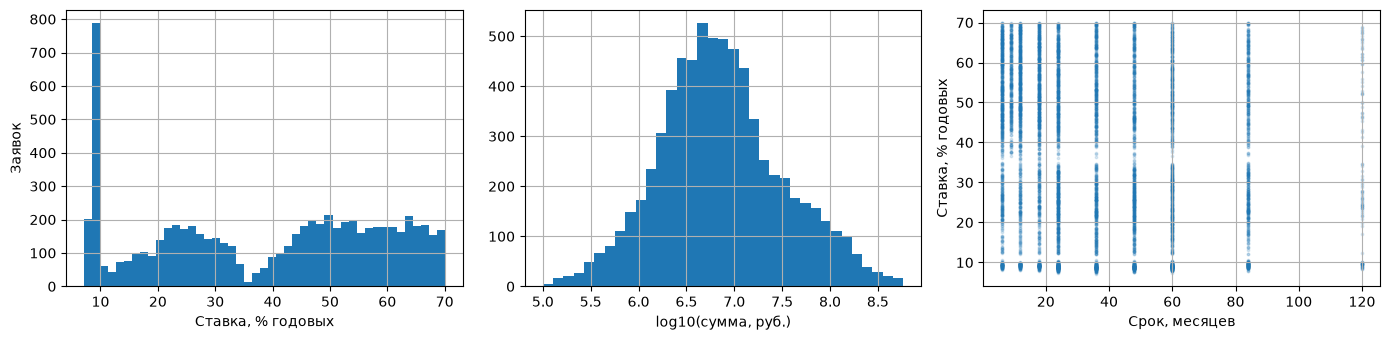

In [8]:
# Показываем распределение ставки и масштабы заявки только на fit.
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].hist(y_fit, bins=45)
axes[0].set(xlabel="Ставка, % годовых", ylabel="Заявок")
axes[1].hist(np.log10(numeric_eda.requested_amount), bins=35)
axes[1].set(xlabel="log10(сумма, руб.)")
axes[2].scatter(numeric_eda.term_months, y_fit, s=3, alpha=.15)
axes[2].set(xlabel="Срок, месяцев", ylabel="Ставка, % годовых")
plt.tight_layout()
plt.show()

## 3. Гипотезы инженерии признаков

| Решение | Причина |
|---|---|
| Идентификаторы и свободные названия | ИНН, id, КПП, уникальные части регистрационных номеров, названия компаний и номера договоров исключаем из матрицы. Они нужны для аудита и сопоставления, но могут запоминать клиента вместо устойчивых зависимостей. |
| Возраст регистрационного номера | Используем приблизительное число лет с присвоения ОГРН/ОГРНИП относительно среза. Оно не равно доказанному фактическому возрасту бизнеса, а неизвестный номер сохраняет пропуск. |
| Финансовые отношения | Вычисляем покрытие залогом, интенсивность погашения основного долга без процентов и нормировку на известную положительную численность. Это универсальные отношения входов, а не восстановление аннуитета или условного бюджета генератора. |
| Пропуски | Неизвестный и нулевой залог или штат сохраняем различимыми, а отношения с неизвестным/нулевым знаменателем оставляем пропущенными. Медианы для Ridge обучаются только на train; CatBoost обрабатывает числовые пропуски непосредственно. |
| Категории и масштаб | CatBoost получает строковые категории и исходные масштабы чисел; Ridge использует one-hot, медианы и стандартизацию внутри train-пайплайна. `log1p` суммы и залога уменьшает разницу масштабов без удаления хвостов. |
| Реестровые сведения | Добавляем категорию региона и способа образования, признаки МСП, участников, преемственности и агрегаты известных правовых событий. Проверяем их отдельной гипотезой, поскольку наличие таких сведений ещё не доказывает полезность для цены кредита. |
| Время | Интервалы считаем относительно `snapshot_on`, а вложенные будущие события исключаем с учётом дат события и записи. Отсутствие `application_at` всё равно не позволяет доказать историческую доступность данных для реальных заявок. |
| Продукция | Из раскрытого списка извлекаем количество, разнообразие групп ОКПД2 и наличие общего признака инновационной/высокотехнологичной продукции. Пустой раскрытый список отличается от отсутствующего блока; свободные названия не кодируются. |
| Партнёрства | Используем число раскрытых записей и интервалы с дат присоединения к программам, доступных на срезе. Эти сведения не трактуются как выручка, суммы поставок или число уникальных контрагентов без надёжных идентификаторов. |
| Пол, страна, гражданство | Сохраняем эти поля и проверяем категориальные признаки в отдельной гипотезе и абляции полного набора. Изменение RMSE не доказывает справедливость или допустимость их применения в реальном кредитовании. |
| Комбинации | Проверяем базу, каждую дополнительную группу и объединение групп при одинаковых параметрах. Эффект объединения нельзя приписывать одному полю без отдельного сравнения. |
| Границы знания | Не используем готовую ставку, коэффициенты генератора, фиксированные процентные надбавки, подстановки 5/40/150 или признаки, рассчитанные из target. Все коэффициенты влияния доступных входов обучаются по данным. |

In [9]:
# Создаём общие признаки без target и выделяем fit и validation.
X_dev = make_features(development.drop(columns="target"))
X_fit = X_dev.iloc[fit_positions].reset_index(drop=True)
X_validation = X_dev.iloc[validation_positions].reset_index(drop=True)
HYPOTHESES = ["raw", "engineered", "registry", "disclosures", "engineered_demographics", "all_without_demographics", "all_features"]
assert set(HYPOTHESES) <= set(FEATURE_SETS)
display(pd.Series({name: len(FEATURE_SETS[name]) for name in HYPOTHESES}, name="признаков").to_frame())

,признаков
raw,9
engineered,19
registry,34
disclosures,28
engineered_demographics,22
all_without_demographics,43
all_features,46


In [10]:
# Проверяем независимость признаков от target и состава пакета.
altered = development.iloc[:3].copy()
altered["target"] = "-999999"
pd.testing.assert_frame_equal(make_features(altered), X_dev.iloc[:3])
pd.testing.assert_frame_equal(make_features(development.iloc[:1]), X_dev.iloc[:1])
forbidden = {"target", "id", "applicant_inn", "legal_name", "ogrn", "ogrnip", "reference_debt_load", "product_margin", "excess_load"}
assert not forbidden.intersection(X_dev.columns)
assert not np.isinf(X_dev.select_dtypes(include="number").to_numpy()).any()
print("Признаки одинаковы для отдельной строки и пакета; target и формула не используются")

Признаки одинаковы для отдельной строки и пакета; target и формула не используются


**Общий контроль.** Все гипотезы сравниваются с заново обученным `engineered` CatBoost на одинаковых 7000/1000 строках с 1000 деревьев, глубиной 6 и штрафом 3. 

**Отбор признаков.** Выбираем наименьший набор среди гипотез в пределах 0,02 п.п. от минимального validation RMSE. Необязательные блоки действительно участвуют в экспериментах, но их сохранение в итоговой модели зависит от измеренного качества.

In [11]:
# Определяем единые метрики и ограничения времени для всех экспериментов.
def metrics(y, prediction):
    residual = np.asarray(prediction) - np.asarray(y)
    return {"rmse": float(np.sqrt(mean_squared_error(y, prediction))),
            "mae": float(mean_absolute_error(y, prediction)), "r2": float(r2_score(y, prediction)),
            "bias": float(residual.mean()), "p95_abs": float(np.quantile(np.abs(residual), .95))}

training_started = time.monotonic()
def check_budget():
    if time.monotonic() - training_started > TOTAL_BUDGET:
        raise RuntimeError("Исчерпан бюджет: эксперимент нельзя объявлять завершённым")

ANCHOR_PARAMS = {"iterations": 1000, "depth": 6, "learning_rate": .05, "l2_leaf_reg": 3., "random_strength": 1., "rsm": 1.}
ANCHOR = {"name": "anchor_engineered", "kind": "catboost", "features": "engineered", "params": ANCHOR_PARAMS}

In [12]:
# Создаём регрессоры с кодированием только тех категорий, которые входят в гипотезу.
def build_model(spec):
    columns = FEATURE_SETS[spec["features"]]
    cats = [name for name in CAT_COLUMNS if name in columns]
    if spec["kind"] == "dummy":
        return DummyRegressor(strategy="mean")
    if spec["kind"] == "catboost":
        return CatBoostRegressor(**spec["params"], loss_function="RMSE", random_seed=SEED,
                                thread_count=THREADS, task_type="CPU", used_ram_limit="1gb",
                                border_count=128, one_hot_max_size=10, allow_writing_files=False,
                                verbose=False, cat_features=cats)
    numeric = [name for name in columns if name not in cats]
    transforms = [("numbers", make_pipeline(SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True), StandardScaler()), numeric)]
    if cats:
        transforms.append(("categories", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cats))
    return make_pipeline(ColumnTransformer(transforms), Ridge(alpha=1.0))

In [13]:
# Используем одинаковый порядок и преобразование столбцов при fit и predict.
def inputs_for(spec, features):
    if spec["kind"] == "dummy":
        return np.zeros((len(features), 1))
    return model_input(features, spec["features"], logarithms=spec["kind"] == "ridge")

def validation_trial(spec):
    check_budget()
    started = time.monotonic()
    model = build_model(spec)
    model.fit(inputs_for(spec, X_fit), y_fit)
    prediction = model.predict(inputs_for(spec, X_validation))
    return {**metrics(y_validation, prediction), "seconds": time.monotonic() - started}

In [14]:
# Измеряем изменение validation RMSE для каждой группы признаков.
hypothesis_rows = []
for feature_set in HYPOTHESES:
    spec = {**ANCHOR, "features": feature_set}
    result = validation_trial(spec)
    hypothesis_rows.append({"features": feature_set, "n_features": len(FEATURE_SETS[feature_set]), **result})
hypothesis_results = pd.DataFrame(hypothesis_rows).set_index("features")
hypothesis_results["delta_vs_engineered"] = hypothesis_results.rmse - hypothesis_results.loc["engineered", "rmse"]
eligible_features = hypothesis_results[hypothesis_results.rmse <= hypothesis_results.rmse.min() + TIE_TOLERANCE]
selected_features = eligible_features.sort_values(["n_features", "rmse"]).index[0]
hypothesis_results.to_csv(ARTIFACTS / "feature_hypotheses.csv")
display(hypothesis_results.sort_values("rmse").round(4))
print("Набор для расширенного поиска:", selected_features)

,n_features,rmse,mae,r2,bias,p95_abs,seconds,delta_vs_engineered
features,,,,,,,,
engineered,19,0.8975,0.6362,0.9979,-0.0535,1.6302,0.6651,0.0000
disclosures,28,0.9124,0.6637,0.9978,-0.0498,1.7534,0.8241,0.0149
engineered_demographics,22,0.9372,0.6511,0.9977,-0.0615,1.7561,0.7203,0.0397
registry,34,0.9473,0.6689,0.9977,-0.0353,1.8623,1.4460,0.0498
all_without_demographics,43,0.9486,0.6884,0.9977,-0.0557,1.7274,1.7514,0.0511
all_features,46,0.9853,0.6920,0.9975,-0.0457,1.8273,1.7836,0.0878
raw,9,2.1585,1.5657,0.9880,0.0338,4.6096,0.5214,1.2610


Набор для расширенного поиска: engineered


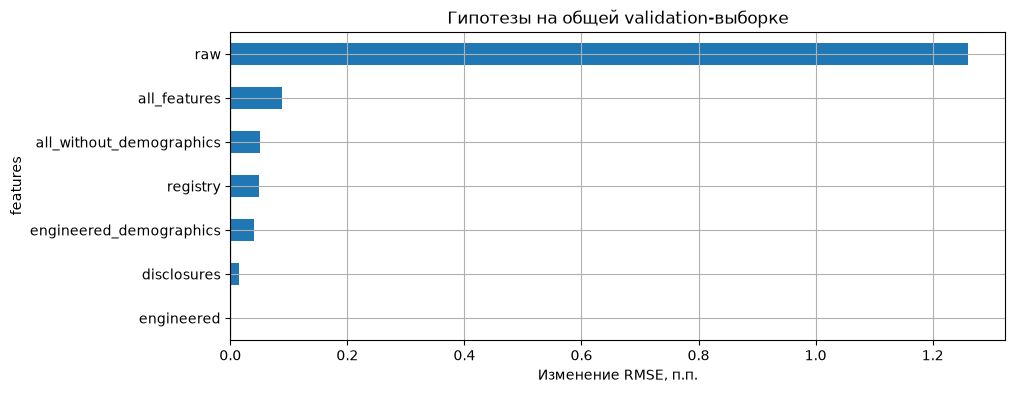

Полный набор минус набор без демографии: +0.0367 п.п.


In [15]:
# Показываем вклад групп относительно контроля и демографическую абляцию.
hypothesis_results.delta_vs_engineered.sort_values().plot.barh(xlabel="Изменение RMSE, п.п.", title="Гипотезы на общей validation-выборке")
plt.axvline(0, color="black")
plt.show()
demographic_delta = hypothesis_results.loc["all_features", "rmse"] - hypothesis_results.loc["all_without_demographics", "rmse"]
print(f"Полный набор минус набор без демографии: {demographic_delta:+.4f} п.п.")

## 4. Поиск гиперпараметров

**Стратегия.** С фиксированным seed заранее генерируем 24 конфигурации случайного поиска и добавляем исходную конфигурацию как контроль. Случайный поиск покрывает шесть параметров без большого декартова произведения, а результаты и статусы каждой попытки сохраняются.

| Параметр | Пространство | Причина |
|---|---|---|
| `depth` | целое 4–8 | Проверяем от неглубоких до более сложных взаимодействий. Глубину ограничиваем ради памяти и времени MacBook. |
| `learning_rate` | log-uniform 0,025–0,12 | Логарифмический диапазон позволяет сравнить осторожные и быстрые обновления. Скорость меняется совместно с числом деревьев. |
| `l2_leaf_reg` | log-uniform 1–30 | Проверяем существенно более широкий диапазон штрафа листьев. Логарифмическая шкала уделяет внимание и слабой, и сильной регуляризации. |
| `iterations` | 800, 1000, 1400, 1800 | Проверяем, окупается ли дополнительное число деревьев. Число фиксировано до fit, поэтому оценочная выборка не выбирает момент остановки. |
| `random_strength` | 0; log-uniform 0,01–3 | Проверяем детерминированный выбор разбиений и несколько уровней его случайного возмущения. Seed остаётся общим для сопоставимости. |
| `rsm` | uniform 0,7–1 | Проверяем долю признаков для выбора разбиения как дополнительную регуляризацию. Нижняя граница сохраняет большую часть информации небольшого набора. |

**Остановка.** Early stopping и pruning отдельных деревьев не используем, чтобы текущая validation не определяла число деревьев внутри trial. При нехватке общего бюджета незапущенные конфигурации получают `skipped_budget`, а ошибки обучения записываются как `failed` и останавливают выполнение.

In [16]:
# Формируем весь план поиска до первого пробного обучения.
search_rng = np.random.default_rng(SEED+20)
search_specs = [{"name": "search_anchor", "kind": "catboost", "features": selected_features, "params": ANCHOR_PARAMS.copy()}]
for trial in range(24):
    params = {"depth": int(search_rng.integers(4, 9)),
              "learning_rate": float(np.exp(search_rng.uniform(np.log(.025), np.log(.12)))),
              "l2_leaf_reg": float(np.exp(search_rng.uniform(np.log(1), np.log(30)))),
              "iterations": int(search_rng.choice([800, 1000, 1400, 1800])),
              "random_strength": 0. if trial % 4 == 0 else float(np.exp(search_rng.uniform(np.log(.01), np.log(3)))),
              "rsm": float(search_rng.uniform(.7, 1.))}
    search_specs.append({"name": f"trial_{trial:02d}", "kind": "catboost", "features": selected_features, "params": params})
search_rows = [{"model": spec["name"], "features": spec["features"], **spec["params"], "status": "pending"} for spec in search_specs]
pd.DataFrame(search_rows).to_csv(ARTIFACTS / "search_results.csv", index=False)

In [17]:
# Выполняем последовательный поиск и сохраняем результат каждой попытки.
for row, spec in zip(search_rows, search_specs):
    if time.monotonic() - training_started >= SEARCH_BUDGET:
        row["status"] = "skipped_budget"
    else:
        try:
            row.update(validation_trial(spec))
            row["status"] = "completed"
        except Exception as error:
            row.update(status="failed", error=repr(error))
            pd.DataFrame(search_rows).to_csv(ARTIFACTS / "search_results.csv", index=False)
            raise
    pd.DataFrame(search_rows).to_csv(ARTIFACTS / "search_results.csv", index=False)
search_results = pd.DataFrame(search_rows)
completed = search_results[search_results.status == "completed"].sort_values("rmse")
assert len(completed) >= 3, "Недостаточно завершённых попыток для отбора"
display(completed.head(10).round(4))
display(search_results.status.value_counts().rename("попыток").to_frame())

,model,features,iterations,depth,learning_rate,l2_leaf_reg,random_strength,rsm,status,rmse,mae,r2,bias,p95_abs,seconds
24,trial_23,engineered,1800,6,0.0626,4.7414,2.6672,0.9535,completed,0.8331,0.6088,0.9982,-0.0529,1.6224,1.2460
19,trial_18,engineered,1800,8,0.0386,2.2444,0.1997,0.7275,completed,0.8410,0.5818,0.9982,-0.0463,1.5216,2.4259
15,trial_14,engineered,1800,7,0.0456,2.2709,0.0248,0.7882,completed,0.8457,0.6025,0.9982,-0.0453,1.4922,1.6636
13,trial_12,engineered,1400,6,0.1031,3.8452,0.0000,0.9875,completed,0.8575,0.5957,0.9981,-0.0571,1.4901,0.9664
8,trial_07,engineered,1400,6,0.0640,3.6577,0.0178,0.8643,completed,0.8622,0.6171,0.9981,-0.0473,1.5312,0.9501
2,trial_01,engineered,1000,7,0.0505,5.2123,0.0459,0.8485,completed,0.8849,0.6278,0.9980,-0.0348,1.6220,0.9200
10,trial_09,engineered,1400,6,0.0343,1.4205,1.0331,0.8304,completed,0.8935,0.6296,0.9979,-0.0245,1.6276,0.9198
0,search_anchor,engineered,1000,6,0.0500,3.0000,1.0000,1.0000,completed,0.8975,0.6362,0.9979,-0.0535,1.6302,0.6808
18,trial_17,engineered,1800,8,0.0621,1.1477,0.0133,0.7115,completed,0.9007,0.6137,0.9979,-0.0338,1.5545,2.4305
12,trial_11,engineered,800,6,0.0756,2.0481,0.1208,0.9370,completed,0.9061,0.6377,0.9979,-0.0547,1.6175,0.5509


,попыток
status,
completed,25


**Анализ поиска.** Показываем качество по глубине, штрафу и скорости обучения, а также фактическую длительность каждой попытки. При 25 совместно меняющихся конфигурациях эти графики не являются причинной оценкой влияния одного параметра или надёжным fANOVA-анализом.

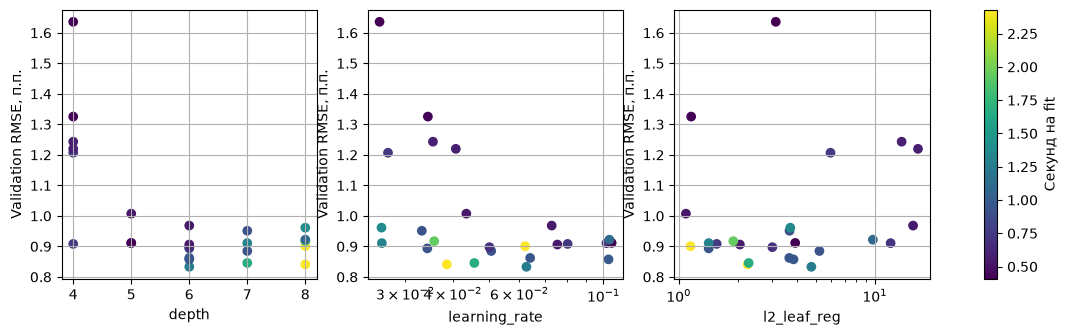

In [18]:
# Визуализируем качество конфигураций и цену вычисления.
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for axis, parameter in zip(axes, ["depth", "learning_rate", "l2_leaf_reg"]):
    scatter = axis.scatter(completed[parameter], completed.rmse, c=completed.seconds, cmap="viridis")
    axis.set(xlabel=parameter, ylabel="Validation RMSE, п.п.")
    if parameter != "depth":
        axis.set_xscale("log")
fig.colorbar(scatter, ax=axes, label="Секунд на fit")
plt.show()

## 5. CV финалистов и заморозка выбора

**Финалисты.** Три лучших завершённых конфигурации поиска сравниваем с прежним инженерным контролем и Ridge на одинаковых трёх блоках только 7000 fit. Validation-тысяча не включается в эти блоки, поскольку её ответы уже использовались для выбора признаков и параметров.

**Сложность.** При разнице RMSE не более 0,02 п.п. предпочитаем линейную модель, затем меньшее `iterations × 2^depth` и меньшее число признаков. После выбора параметры фиксируются, а повторные holdout-ошибки не запускают новый поиск.

In [19]:
# Формируем финалистов и заранее определённый порядок простоты.
by_search_name = {spec["name"]: spec for spec in search_specs}
finalists = [by_search_name[name] for name in completed.head(3).model]
finalists += [ANCHOR, {"name": "ridge_raw", "kind": "ridge", "features": "raw", "params": {}}]
BY_NAME = {spec["name"]: spec for spec in finalists}

def complexity(spec):
    if spec["kind"] == "ridge":
        return (0, 0, len(FEATURE_SETS[spec["features"]]))
    return (1, spec["params"]["iterations"] * 2**spec["params"]["depth"], len(FEATURE_SETS[spec["features"]]))

In [20]:
# Собираем OOF-прогнозы без использования оцениваемого блока в fit.
fold_rows, oof_predictions = [], {}
for spec in finalists:
    prediction = np.full(len(y_fit), np.nan)
    for fold, (train, valid) in enumerate(folds):
        check_budget()
        started = time.monotonic()
        model = build_model(spec)
        model.fit(inputs_for(spec, X_fit.iloc[train]), y_fit.iloc[train])
        train_prediction = model.predict(inputs_for(spec, X_fit.iloc[train]))
        prediction[valid] = model.predict(inputs_for(spec, X_fit.iloc[valid]))
        fold_rows.append({"model": spec["name"], "fold": fold, **metrics(y_fit.iloc[valid], prediction[valid]),
                          "train_rmse": metrics(y_fit.iloc[train], train_prediction)["rmse"],
                          "seconds": time.monotonic() - started})
    assert np.isfinite(prediction).all()
    oof_predictions[spec["name"]] = prediction
fold_results = pd.DataFrame(fold_rows)

In [21]:
# Выбираем обученную модель по pooled OOF RMSE и сохраняем доказательства.
cv_results = pd.DataFrame([{"model": name, **metrics(y_fit, prediction)} for name, prediction in oof_predictions.items()]).set_index("model")
cv_results["fold_rmse_std"] = fold_results.groupby("model").rmse.std()
cv_results["train_rmse"] = fold_results.groupby("model").train_rmse.mean()
cv_results["seconds"] = fold_results.groupby("model").seconds.sum()
eligible = cv_results[cv_results.rmse <= cv_results.rmse.min() + TIE_TOLERANCE]
selected_name = min(eligible.index, key=lambda name: (complexity(BY_NAME[name]), cv_results.loc[name, "rmse"]))
selected_spec = BY_NAME[selected_name]
fold_results.to_csv(ARTIFACTS / "cv_folds.csv", index=False)
cv_results.to_csv(ARTIFACTS / "cv_results.csv")
pd.DataFrame({"id": fit_raw.id, "target": y_fit, **oof_predictions}).to_csv(ARTIFACTS / "oof_predictions.csv", index=False)
display(cv_results.sort_values("rmse").round(4))
print("Выбрана модель:", selected_name, selected_spec)

,rmse,mae,r2,bias,p95_abs,fold_rmse_std,train_rmse,seconds
model,,,,,,,,
trial_14,1.1047,0.6606,0.9969,-0.0149,1.6483,0.0620,0.3861,4.2395
anchor_engineered,1.1116,0.6856,0.9968,-0.0073,1.6843,0.0838,0.6048,1.7321
trial_18,1.1299,0.6620,0.9967,-0.0201,1.6675,0.0430,0.3486,6.5518
trial_23,1.1401,0.6913,0.9967,-0.0118,1.6981,0.0521,0.4492,3.0608
ridge_raw,10.9601,8.9112,0.6924,-0.0129,20.7146,0.1763,10.9050,0.0463


Выбрана модель: anchor_engineered {'name': 'anchor_engineered', 'kind': 'catboost', 'features': 'engineered', 'params': {'iterations': 1000, 'depth': 6, 'learning_rate': 0.05, 'l2_leaf_reg': 3.0, 'random_strength': 1.0, 'rsm': 1.0}}


**Кривая обучения.** Для уже выбранной конфигурации используем пять вложенных размеров train на одном фиксированном CV-блоке из fit. Это ограниченная по ресурсам диагностика разрыва train/validation, а не новая независимая оценка или основание менять параметры.

In [22]:
# Проверяем зависимость ошибки выбранной модели от объёма обучения.
curve_train, curve_valid = folds[0]
curve_train = np.random.default_rng(SEED+30).permutation(curve_train)
curve_rows = []
for fraction in [.2, .4, .6, .8, 1.]:
    check_budget()
    subset = curve_train[:int(len(curve_train)*fraction)]
    curve_model = build_model(selected_spec)
    curve_model.fit(inputs_for(selected_spec, X_fit.iloc[subset]), y_fit.iloc[subset])
    curve_rows.append({"n": len(subset),
                       "train_rmse": metrics(y_fit.iloc[subset], curve_model.predict(inputs_for(selected_spec, X_fit.iloc[subset])))["rmse"],
                       "validation_rmse": metrics(y_fit.iloc[curve_valid], curve_model.predict(inputs_for(selected_spec, X_fit.iloc[curve_valid])))["rmse"]})
learning_curve = pd.DataFrame(curve_rows)
learning_curve.to_csv(ARTIFACTS / "learning_curve.csv", index=False)

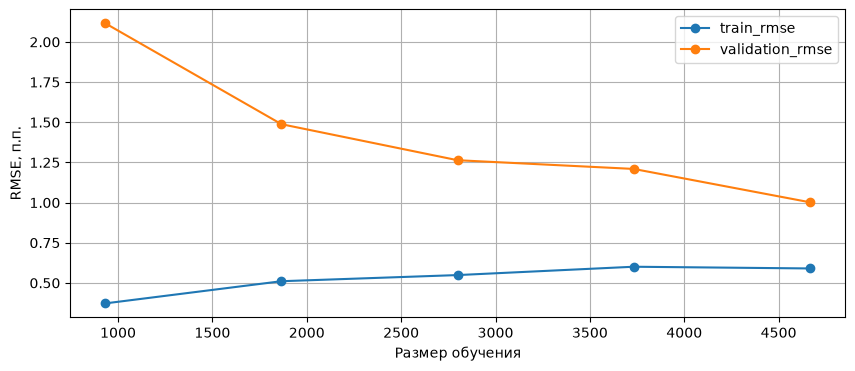

,n,train_rmse,validation_rmse
0,933,0.3728,2.1154
1,1866,0.5107,1.4879
2,2799,0.5489,1.2637
3,3732,0.6008,1.2095
4,4666,0.5901,1.0020


In [23]:
# Сопоставляем train и validation на пяти размерах подвыборки.
learning_curve.plot(x="n", y=["train_rmse", "validation_rmse"], marker="o", ylabel="RMSE, п.п.", xlabel="Размер обучения")
plt.show()
display(learning_curve.round(4))

## 6. Повторная диагностика и срезы

**Финальное обучение.** Выбранную модель, контроль с прежними признаками и линейный baseline обучаем на всех 8000 development, включая validation после заморозки выбора. Ни одна из 2000 holdout-строк не входит в fit, но просмотренные ранее метрики не позволяют считать эту проверку новой независимой оценкой.

In [24]:
# Обучаем зафиксированные модели на всех development-строках.
final_specs = {spec["name"]: spec for spec in [selected_spec, ANCHOR, BY_NAME["ridge_raw"]]}
fitted = {}
for name, spec in final_specs.items():
    check_budget()
    model = build_model(spec)
    model.fit(inputs_for(spec, X_dev), y_dev)
    fitted[name] = model
training_seconds = time.monotonic() - training_started

In [25]:
# Оцениваем только зафиксированные модели на прежнем диагностическом holdout.
test = raw.iloc[test_idx].reset_index(drop=True)
y_test = y_all.iloc[test_idx].to_numpy()
X_test = make_features(test.drop(columns="target"))
test_predictions = {"dummy_mean": np.full(len(test), y_dev.mean())}
for name, model in fitted.items():
    test_predictions[name] = np.asarray(model.predict(inputs_for(final_specs[name], X_test)))
holdout_results = pd.DataFrame({name: metrics(y_test, prediction) for name, prediction in test_predictions.items()}).T
display(holdout_results.round(4))

,rmse,mae,r2,bias,p95_abs
dummy_mean,19.5531,17.3764,-0.0000,0.1104,30.1812
anchor_engineered,1.0145,0.6416,0.9973,0.0514,1.6393
ridge_raw,10.9129,8.8826,0.6885,0.2425,21.0339


**Интервалы.** Для фиксированных моделей рассчитываем 95% bootstrap-интервалы и парную разницу RMSE выбранной модели относительно инженерного контроля. Эти интервалы условны относительно выборки и не учитывают поиск лучшей конфигурации, поэтому не объявляем ими статистически доказанную победу среди множества гипотез.

In [26]:
# Получаем воспроизводимые bootstrap-выборки без больших матриц в памяти.
rng = np.random.default_rng(SEED+40)
bootstrap_values = {name: [] for name in test_predictions}
paired_differences = []
for _ in range(BOOTSTRAPS):
    draw = rng.integers(0, len(test), len(test))
    for name, prediction in test_predictions.items():
        bootstrap_values[name].append(metrics(y_test[draw], prediction[draw]))
    paired_differences.append(bootstrap_values[selected_name][-1]["rmse"] - bootstrap_values["anchor_engineered"][-1]["rmse"])

In [27]:
# Сводим интервалы метрик и парную диагностическую разницу ошибок.
interval_rows = []
for name, samples in bootstrap_values.items():
    for metric in holdout_results.columns:
        low, high = np.quantile([sample[metric] for sample in samples], [.025, .975])
        interval_rows.append({"model": name, "metric": metric, "estimate": holdout_results.loc[name, metric], "low_95": low, "high_95": high})
intervals = pd.DataFrame(interval_rows)
paired_ci = np.quantile(paired_differences, [.025, .975])
paired_delta = holdout_results.loc[selected_name, "rmse"] - holdout_results.loc["anchor_engineered", "rmse"]
display(intervals.round(4))
print("RMSE модели минус инженерный контроль:", paired_delta, "95% диагностический интервал:", paired_ci)

,model,metric,estimate,low_95,high_95
0,dummy_mean,rmse,19.5531,19.1873,19.8668
1,dummy_mean,mae,17.3764,16.9800,17.7296
2,dummy_mean,r2,-0.0000,-0.0025,-0.0000
3,dummy_mean,bias,0.1104,-0.7133,0.9520
4,dummy_mean,p95_abs,30.1812,30.1202,30.3002
5,anchor_engineered,rmse,1.0145,0.8921,1.1399
6,anchor_engineered,mae,0.6416,0.6091,0.6756
7,anchor_engineered,r2,0.9973,0.9966,0.9979
8,anchor_engineered,bias,0.0514,0.0090,0.0967
9,anchor_engineered,p95_abs,1.6393,1.4890,1.7451


RMSE модели минус инженерный контроль: 0.0 95% диагностический интервал: [0. 0.]


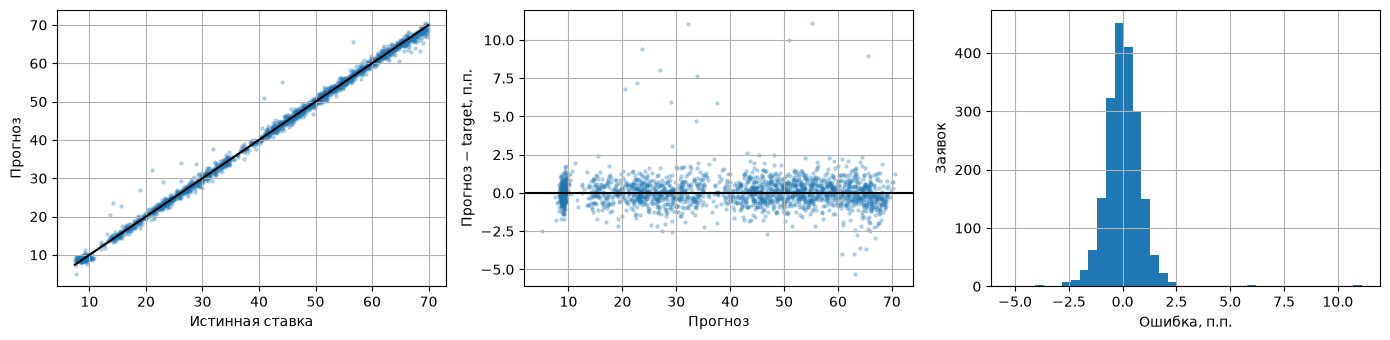

In [28]:
# Показываем остатки выбранной модели без дальнейшего изменения параметров.
chosen_prediction = test_predictions[selected_name]
residual = chosen_prediction - y_test
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].scatter(y_test, chosen_prediction, s=5, alpha=.25)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="black")
axes[0].set(xlabel="Истинная ставка", ylabel="Прогноз")
axes[1].scatter(chosen_prediction, residual, s=5, alpha=.25)
axes[1].axhline(0, color="black")
axes[1].set(xlabel="Прогноз", ylabel="Прогноз − target, п.п.")
axes[2].hist(residual, bins=40)
axes[2].set(xlabel="Ошибка, п.п.", ylabel="Заявок")
plt.tight_layout()
plt.show()

**Срезы.** Показываем ошибки по параметрам заявки, пропускам, полу, гражданству и стране с числом строк в каждой группе. Малые группы не дают устойчивой оценки, а одинаковый RMSE по группам не является достаточной проверкой справедливости.

In [29]:
# Формируем групповые диагностические метрики с явным размером каждого среза.
slices = {"диапазон_ставки": pd.Series(rate_band(y_test)),
          **{name: test[name].replace("", "__MISSING__") for name in ["applicant_entity_type", "msp_category", "financing_purpose", "payment_frequency", "sex", "citizenship_kind", "country_code_raw"]},
          "нет_численности": test.average_headcount.eq(""), "нет_залога": test.declared_collateral_value.eq(""),
          "срок_до_18": X_test.term_months.le(18), "сумма_более_150млн": X_test.requested_amount.gt(150000000)}
slice_rows = []
for field, values in slices.items():
    for value in values.unique():
        mask = np.asarray(values == value)
        if mask.sum() >= 2:
            slice_rows.append({"slice": field, "value": str(value), "n": int(mask.sum()), **metrics(y_test[mask], chosen_prediction[mask])})
slice_results = pd.DataFrame(slice_rows)
display(slice_results.round(3))

,slice,value,n,rmse,mae,r2,bias,p95_abs
0,диапазон_ставки,низкая,300,0.631,0.485,-0.037,0.021,1.283
1,диапазон_ставки,обычная,600,1.198,0.687,0.961,0.125,1.673
2,диапазон_ставки,высокая,1100,0.990,0.659,0.988,0.019,1.729
3,applicant_entity_type,legal_entity,1333,0.756,0.589,0.999,0.013,1.477
4,applicant_entity_type,ip,667,1.395,0.747,0.995,0.129,2.013
5,msp_category,micro,1443,0.767,0.583,0.998,0.003,1.510
6,msp_category,small,473,1.404,0.780,0.995,0.167,1.930
7,msp_category,medium,84,1.814,0.864,0.991,0.226,1.905
8,financing_purpose,working_capital,684,1.013,0.637,0.997,0.034,1.628
9,financing_purpose,commercial_mortgage,123,0.780,0.587,0.998,-0.030,1.747


**Важность признаков.** Для выбранного CatBoost показываем встроенную важность, вычисленную при обучении на development, а для Ridge — коэффициенты после стандартизации. Это описание обученного предиктора, а не причинное влияние поля на кредитоспособность.

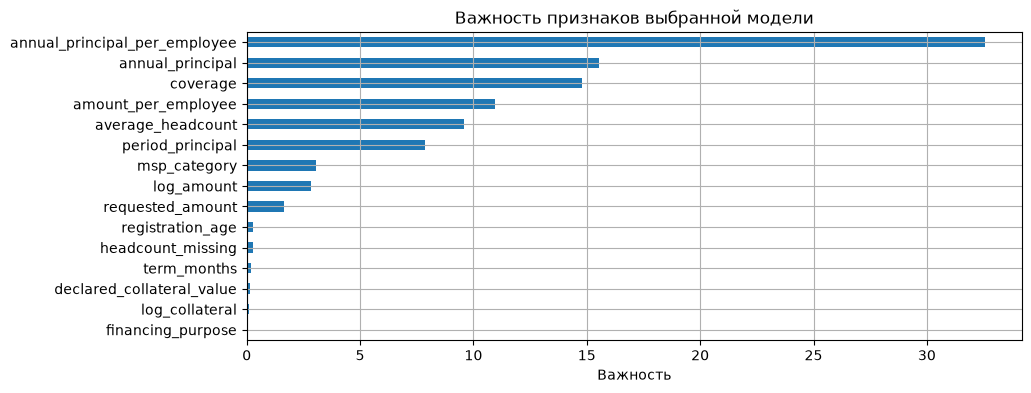

In [30]:
# Объясняем структуру выбранной модели по её обученным параметрам.
selected_model = fitted[selected_name]
if selected_spec["kind"] == "catboost":
    importance = pd.Series(selected_model.feature_importances_, index=FEATURE_SETS[selected_spec["features"]]).sort_values()
    importance.tail(15).plot.barh(title="Важность признаков выбранной модели", xlabel="Важность")
    plt.show()
else:
    display(pd.Series(selected_model[-1].coef_, index=selected_model[0].get_feature_names_out(), name="коэффициент").to_frame())

## 7. Применение, экспорт и уборка

**Один итоговый артефакт модели.** Сохраняем `selected_model.joblib` с обученным estimator, схемой и хешем признаков. После анализа и проверки прогнозов удаляем временные таблицы и прежний внешний манифест по явному списку; метрики, графики и сводка запуска остаются внутри ноутбука.

**Самостоятельный прогноз.** `Scorer.__init__` создаёт pipeline сохранённой модели и общей предобработки, а `await scorer.predict(row)` принимает одну запись без target и возвращает float. Проверяем совпадение прогнозов с estimator; подготовка и вычисление выполняются в рабочем потоке.

In [31]:
# Сохраняем обученный estimator вместе с контрактом признаков.
bundle = {"estimator": selected_model, "spec": selected_spec,
          "feature_columns": list(inputs_for(selected_spec, X_dev).columns),
          "feature_version": FEATURE_VERSION, "feature_source_sha256": FEATURE_SHA256,
          "data_sha256": DATA_SHA256, "training_scope": "8000 development rows"}
joblib.dump(bundle, ARTIFACTS / "selected_model.joblib")
scorer = Scorer(ARTIFACTS / "selected_model.joblib")
predictions = [await scorer.predict(row) for row in test.drop(columns="target").to_dict("records")]
np.testing.assert_allclose(predictions, chosen_prediction)
rate = await scorer.predict(test.iloc[0].drop(labels="target").to_dict())
assert isinstance(rate, float)
np.testing.assert_allclose(rate, chosen_prediction[0])
print("Асинхронные прогнозы отдельных заявок совпадают с estimator; пример ставки:", rate)

Асинхронные прогнозы отдельных заявок совпадают с estimator; пример ставки: 9.331403678972208


In [32]:
# Временно записываем диагностику и фиксируем контрольные суммы перед уборкой.
intervals.to_csv(ARTIFACTS / "holdout_intervals.csv", index=False)
slice_results.to_csv(ARTIFACTS / "holdout_slices.csv", index=False)
pd.DataFrame({"id": test.id, "target": y_test, **test_predictions}).to_csv(ARTIFACTS / "holdout_predictions.csv", index=False)
RUN_ARTIFACTS = ["selected_model.joblib", "split.csv", "feature_hypotheses.csv", "search_results.csv",
                  "cv_folds.csv", "cv_results.csv", "oof_predictions.csv", "learning_curve.csv",
                  "holdout_intervals.csv", "holdout_slices.csv", "holdout_predictions.csv"]
artifact_hashes = {name: hashlib.sha256((ARTIFACTS / name).read_bytes()).hexdigest() for name in RUN_ARTIFACTS}

In [33]:
# Связываем отчёт с исполняемыми ячейками, исходниками и измеренными ресурсами.
notebook_document = json.loads((SCORER_DIR / "scorer.ipynb").read_text(encoding="utf-8"))
code_sources = ["".join(cell["source"]) for cell in notebook_document["cells"] if cell["cell_type"] == "code"]
notebook_code_hash = hashlib.sha256(json.dumps(code_sources, ensure_ascii=False).encode()).hexdigest()
peak_rss = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
peak_rss_mb = peak_rss / (1024**2 if platform.system() == "Darwin" else 1024)
selected_metrics = holdout_results.loc[selected_name]
improvement = 1 - selected_metrics.rmse / holdout_results.loc["dummy_mean", "rmse"]
acceptance_passed = bool(selected_metrics.rmse <= 1 and improvement >= .8)

In [34]:
# Собираем сведения о запуске для сохранения внутри ноутбука.
manifest = {"selected": selected_name, "selected_spec": selected_spec, "feature_version": FEATURE_VERSION,
            "feature_sets": FEATURE_SETS, "selected_features": selected_spec["features"],
            "input_columns": [name for name in EXPECTED_COLUMNS if name != "target"],
            "data_sha256": DATA_SHA256, "feature_source_sha256": FEATURE_SHA256,
            "scorer_source_sha256": hashlib.sha256((SCORER_DIR / "scorer.py").read_bytes()).hexdigest(),
            "notebook_code_sha256": notebook_code_hash, "artifact_sha256": artifact_hashes,
            "python": platform.python_version(), "versions": VERSIONS, "seed": SEED,
            "split_sizes": {"fit": 7000, "hypothesis_validation": 1000, "diagnostic_holdout": 2000},
            "holdout_status": "reused diagnostic holdout; not independent evidence",
            "rule": "validation feature/search screening; fit-only pooled OOF RMSE; simplicity within 0.02 pp",
            "search_completed": int((search_results.status == "completed").sum()), "search_planned": len(search_specs),
            "cv_rmse": float(cv_results.loc[selected_name, "rmse"]), "test_metrics": holdout_results.to_dict(orient="index"),
            "paired_rmse_delta_selected_minus_anchor": float(paired_delta), "paired_ci_95": paired_ci.tolist(),
            "acceptance_passed": acceptance_passed, "improvement_vs_mean": float(improvement),
            "training_seconds": training_seconds, "peak_process_rss_mb": peak_rss_mb, "thread_count": THREADS}

In [35]:
# Сохраняем сводку в выводе ноутбука и удаляем использованные временные файлы.
display({"application/json": {"experiment_summary": {"manifest": manifest}},
         "text/plain": "Сведения о запуске и метрики сохранены в JSON-выводе этой ячейки."}, raw=True)
TEMPORARY_ARTIFACTS = [name for name in RUN_ARTIFACTS if name != "selected_model.joblib"]
TEMPORARY_ARTIFACTS += ["experiment_manifest.json", "selected_ml.joblib", "best_catboost.cbm", "selection.json", "holdout_metrics.csv"]
removed = []
for name in TEMPORARY_ARTIFACTS:
    path = ARTIFACTS / name
    if path.is_file():
        path.unlink()
        removed.append(name)
print("Удалены временные артефакты:", removed)
print(f"Обучение, подбор и CV (до holdout/bootstrap): {training_seconds:.1f} с; пик RSS процесса: {peak_rss_mb:.1f} МиБ")

Сведения о запуске и метрики сохранены в JSON-выводе этой ячейки.

Удалены временные артефакты: []
Обучение, подбор и CV (до holdout/bootstrap): 51.9 с; пик RSS процесса: 558.4 МиБ


## 8. Выводы

Выбрана обученная модель **anchor_engineered** с набором **engineered** (19 признаков), OOF RMSE на 7000 fit составляет **1.1116 п.п.** Выбор сделан по CV с заранее заданным допуском 0,02 п.п. и предпочтением простоты.

На повторно используемом диагностическом holdout RMSE равна **1.0145 п.п.**, MAE — **0.6416 п.п.**, R² — **0.99731**. Инженерный контроль при том же финальном объёме обучения имеет RMSE **1.0145 п.п.**

Проверены **7 гипотез признаков**; добавление демографии к полному набору изменило validation RMSE на **+0.0367 п.п.** Продукция, партнёрства и реестровые сведения участвовали в отдельных сравнениях, поэтому их эффект виден в таблице гипотез.

Завершено **25 из 25** конфигураций расширенного поиска. Параметры выбранной модели: `iterations=1000`, `depth=6`, `learning_rate=0.05`, `l2_leaf_reg=3`, `random_strength=1`, `rsm=1`.

Ориентир RMSE ≤ 1 п.п. и улучшение относительно среднего ≥80% **не выполнен**; измеренное улучшение составляет **94.8%**. Обучение, подбор и CV заняли **51.9 с** (до holdout/bootstrap), пик RSS процесса — **558.4 МиБ**.

Для квартальных платежей диагностическая RMSE равна **2.9492 п.п.** на **46 заявках**, что хуже общей ошибки. Малый сегмент требует отдельной проверки на новых наблюдениях; параметры по этому результату не изменялись.

Итоговый `selected_model.joblib` загружается через `Scorer`; временные таблицы и внешний манифест удаляются после анализа. Из-за синтетических данных, отбора гипотез и уже просмотренного holdout результаты не заменяют новую временную проверку после переобучения на реальных данных.